In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from plot_style import C, apply

FIG = Path("figs")
DATA_PATH = FIG / "data" / "slow_switch_residence_data.npz"
OUTPUT = FIG / "Fig13.pdf"

apply()

with np.load(DATA_PATH) as saved:
    dwells = {key: saved[f"dwells_{key}"] for key in "ABCD"}

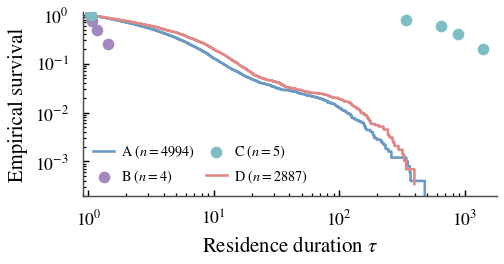

In [2]:
fig, ax = plt.subplots(figsize=(3.35, 1.75))
styles = (
    ("A", C["blue"]),
    ("B", C["purple"]),
    ("C", C["teal"]),
    ("D", C["red"]),
)
for key, color in styles:
    durations = np.sort(dwells[key])
    survival = 1.0 - np.arange(durations.size) / durations.size
    label = f"{key} ($n={durations.size}$)"
    if durations.size < 20:
        ax.scatter(durations, survival, color=color, s=21,
                   marker="o", label=label, zorder=4)
    else:
        ax.step(durations, survival, where="post", color=color,
                linewidth=1.25, label=label)

ax.set(xscale="log", yscale="log", xlabel=r"Residence duration $\tau$",
       ylabel="Empirical survival")
ax.set_xlim(0.9, 1800)
ax.set_ylim(2e-4, 1.15)
ax.legend(loc="lower left", ncol=2, fontsize=6.8, frameon=False,
          handlelength=1.45, columnspacing=0.8)
ax.tick_params(which="both", top=False, right=False, direction="in", pad=6.5)
for s in ("left", "bottom"):
    ax.spines[s].set_color("0.3")
fig.tight_layout(pad=0.35)
fig.savefig(OUTPUT)
plt.show()